# Step 3: Visualising drift

**Goal:** show with pictures and numbers that sensor behaviour changes from batch to batch.

Rules followed here:
- The scaler and PCA are **fitted on the training batches (1-3) only**, then applied to all batches.
- The Dennler-style check at the end is a **proxy**: this dataset version does not contain the raw pre-exposure
  baseline used in that paper, so we cannot reproduce their analysis exactly.
- This is descriptive analysis. Nothing is tuned or selected on later batches.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from src import data_loader as dl
from src import drift

pd.set_option("display.width", 150)
df = dl.remove_toluene(dl.load_all())
GASES = ["Ethanol", "Ethylene", "Ammonia", "Acetaldehyde", "Acetone"]
GAS_COLORS = dict(zip(GASES, sns.color_palette("tab10")[:5]))
print("Rows:", len(df), "| training batches:", drift.TRAIN_BATCHES)

Rows: 12077 | training batches: (1, 2, 3)


## 1. Same gas, different batch: how do raw readings change?

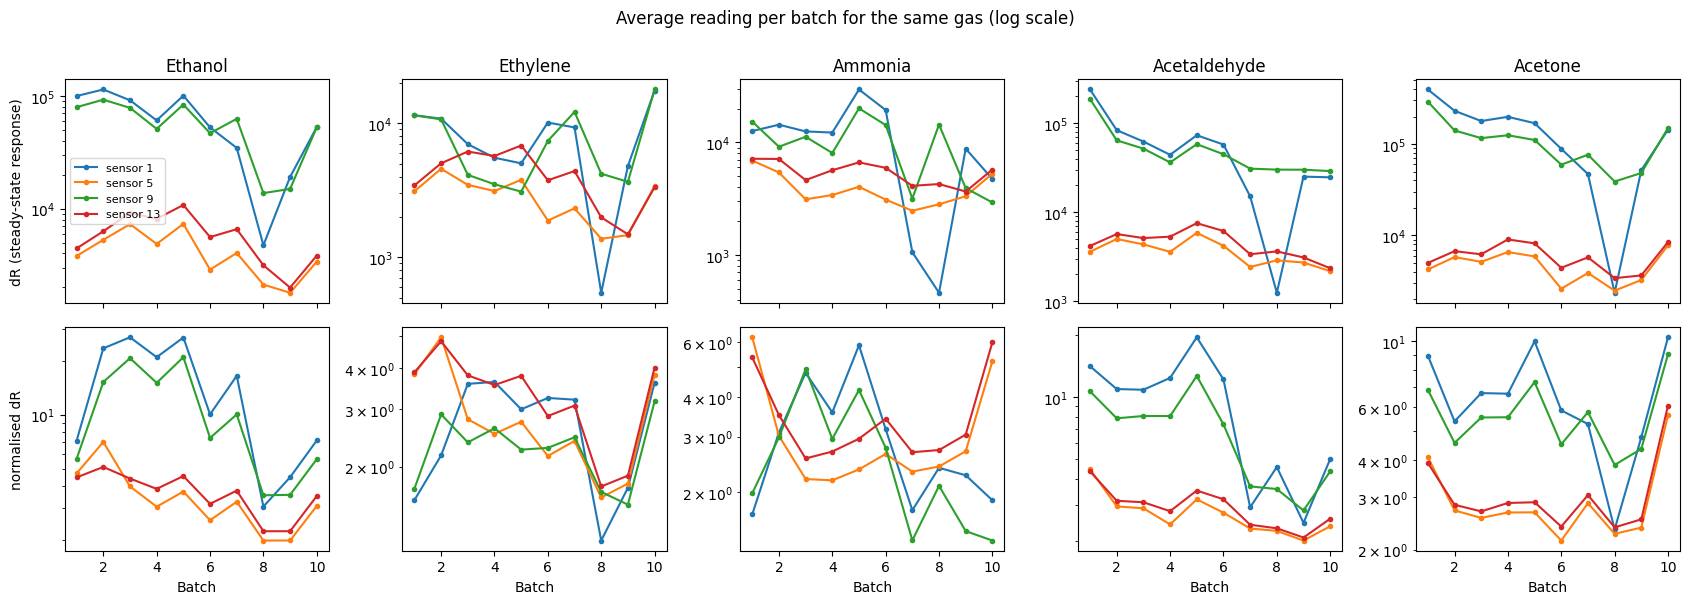

In [2]:
# sensors 1, 5, 9, 13; feature 1 of a sensor is dR, feature 2 is normalised dR
sensors = [1, 5, 9, 13]
fig, axes = plt.subplots(2, 5, figsize=(17, 6), sharex=True)
for col_i, gas in enumerate(GASES):
    sub = df[df["gas"] == gas]
    for row_i, (offset, name) in enumerate([(0, "dR (steady-state response)"), (1, "normalised dR")]):
        ax = axes[row_i, col_i]
        for s in sensors:
            feat = f"f{(s - 1) * 8 + 1 + offset}"
            means = sub.groupby("batch")[feat].mean()
            ax.plot(means.index, means.values, marker="o", ms=3, label=f"sensor {s}")
        ax.set_yscale("log")
        ax.set_title(f"{gas}" if row_i == 0 else "")
        if col_i == 0:
            ax.set_ylabel(name)
        if row_i == 1:
            ax.set_xlabel("Batch")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Average reading per batch for the same gas (log scale)", y=1.0)
plt.tight_layout()
plt.savefig("../results/step3_sensor_means.png", dpi=150)
plt.show()

**What to notice:** for the same gas, the average reading of a sensor changes a lot from batch to batch, often by
a factor of several and sometimes by an order of magnitude (for example, sensor 1 for Acetaldehyde falls from about
240,000 in batch 1 to about 1,200 in batch 8). The changes are not a smooth decline: values go up and down, and
different sensors behave differently (sensors 1 and 9 sit much higher than 5 and 13).

**Caution:** the gas concentration also changed between batches in the original experiment and is not included in
this dataset version, so part of these changes may be concentration and not only sensor ageing. We cannot separate
the two here.

## 2. PCA: do the batches drift apart in feature space?

Variance explained by PC1, PC2 (training batches): [0.44  0.227]


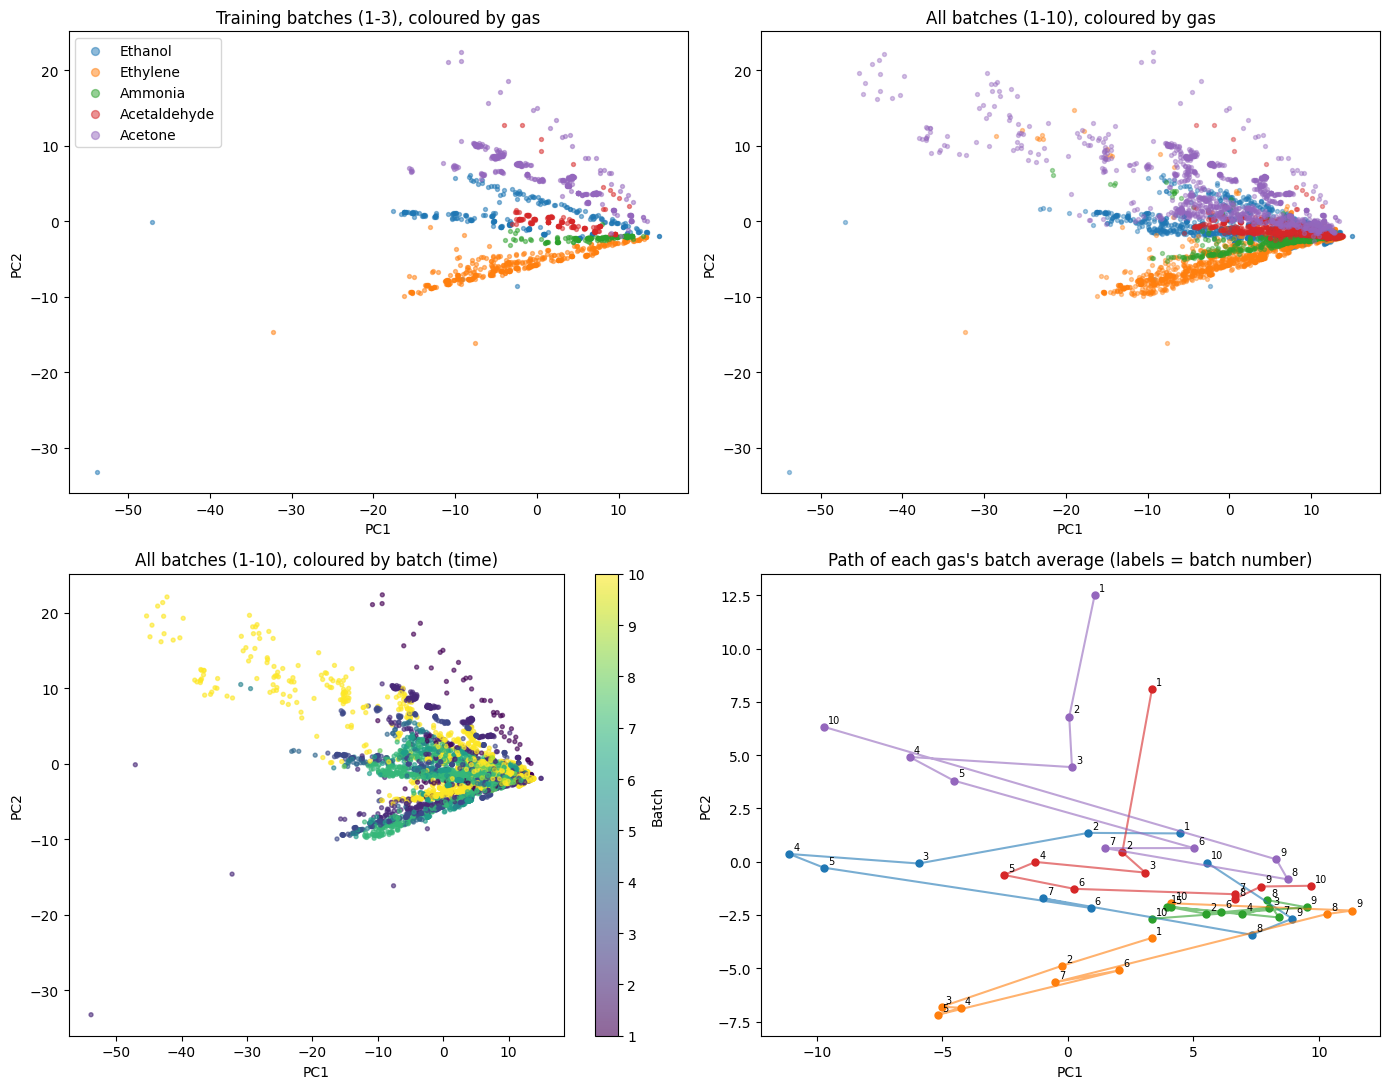

In [3]:
scaler, pca = drift.fit_scaler_pca(df, n_components=2)
coords = drift.project(df, scaler, pca)
df["pc1"], df["pc2"] = coords[:, 0], coords[:, 1]
print("Variance explained by PC1, PC2 (training batches):", pca.explained_variance_ratio_.round(3))

train_mask = df["batch"].isin(drift.TRAIN_BATCHES)
plot_df = df.sample(n=5000, random_state=42)   # subsample only to keep the plot readable

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
ax = axes[0, 0]
t = plot_df[plot_df["batch"].isin(drift.TRAIN_BATCHES)]
for g in GASES:
    s = t[t["gas"] == g]
    ax.scatter(s["pc1"], s["pc2"], s=8, alpha=0.5, color=GAS_COLORS[g], label=g)
ax.set_title("Training batches (1-3), coloured by gas")
ax.legend(markerscale=2)

ax = axes[0, 1]
for g in GASES:
    s = plot_df[plot_df["gas"] == g]
    ax.scatter(s["pc1"], s["pc2"], s=8, alpha=0.4, color=GAS_COLORS[g], label=g)
ax.set_title("All batches (1-10), coloured by gas")

ax = axes[1, 0]
sc = ax.scatter(plot_df["pc1"], plot_df["pc2"], c=plot_df["batch"], cmap="viridis", s=8, alpha=0.6)
plt.colorbar(sc, ax=ax, label="Batch")
ax.set_title("All batches (1-10), coloured by batch (time)")

ax = axes[1, 1]
centroids = df.groupby(["gas", "batch"])[["pc1", "pc2"]].mean()
for g in GASES:
    c = centroids.loc[g]
    ax.plot(c["pc1"], c["pc2"], "-", color=GAS_COLORS[g], alpha=0.6)
    ax.scatter(c["pc1"], c["pc2"], color=GAS_COLORS[g], s=25)
    for b, (x, y) in c.iterrows():
        ax.annotate(str(b), (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("Path of each gas's batch average (labels = batch number)")
for a in axes.ravel():
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout()
plt.savefig("../results/step3_pca_drift.png", dpi=150)
plt.show()

**What to notice** (PC1 + PC2 together explain about 67% of the variance in the training batches):
- **Top-left:** in the training batches the gases form fairly separate bands, so a classifier has clear structure to learn.
- **Top-right:** when all batches are added, the gases overlap heavily in the dense region on the right.
- **Bottom-left:** batch 10 (yellow) has many points far to the upper left, in a region the training batches
  (dark purple) never covered, which is mostly Acetone. A model trained on early batches has never seen this region.
- **Bottom-right:** the average position of each gas moves from batch to batch and does not return to its
  starting point. The path is jumpy and not a straight line.

PCA here is only a 2-D picture of a 128-D space, so overlaps in the picture do not prove that the gases are
inseparable in the full space.

## 3. Measuring drift with a number

In [4]:
shift, between = drift.centroid_shift(df, scaler)
print(f"Average distance between different gases in the training batches: {between:.1f}")
shift.round(1)

Average distance between different gases in the training batches: 9.0


,Acetaldehyde,Acetone,Ammonia,Ethanol,Ethylene
1,9.2,8.3,4.9,8.2,6.8
2,1.1,0.8,2.0,4.3,3.7
3,1.1,2.6,2.4,3.8,3.7
4,11.8,7.2,1.6,19.5,5.2
5,5.8,6.3,3.2,7.6,4.3
6,4.2,8.0,2.4,6.4,5.7
7,5.2,6.8,3.5,5.1,4.8
8,5.2,11.6,3.8,11.7,13.5
9,5.8,11.0,4.2,12.8,14.4
10,7.4,12.9,5.1,9.0,8.3


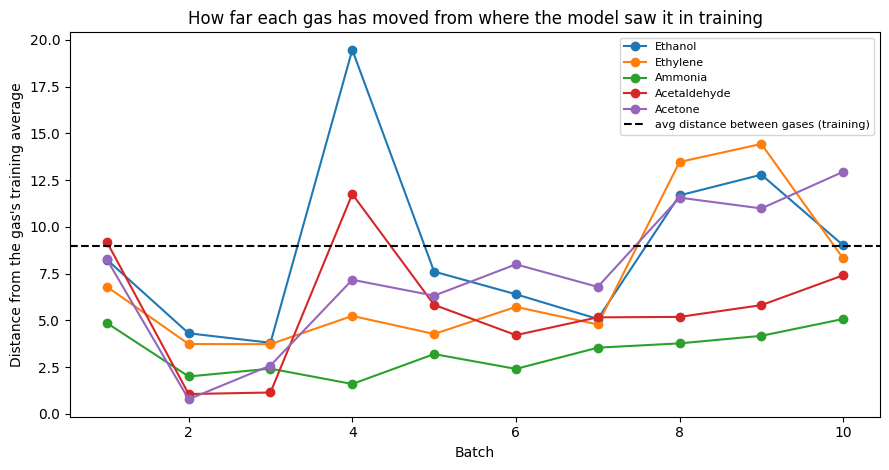

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for g in GASES:
    ax.plot(shift.index, shift[g], marker="o", color=GAS_COLORS[g], label=g)
ax.axhline(between, color="black", ls="--", label="avg distance between gases (training)")
ax.set_xlabel("Batch")
ax.set_ylabel("Distance from the gas's training average")
ax.set_title("How far each gas has moved from where the model saw it in training")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("../results/step3_centroid_shift.png", dpi=150)
plt.show()
shift.round(2).to_csv("../results/step3_centroid_shift.csv")

**How the number is computed:** for each gas we take its average position (centroid) in the 128-D scaled space in
the training batches (1-3), and measure how far its average in each batch is from that. The dashed line is the typical
distance between two *different* gases in training (9.0). If a gas has moved further than that, a model built on
the training batches can easily confuse it with another gas.

**What to notice:**
- **Ammonia stays close** to its training position (never above about 5.1).
- **Ethanol in batch 4 moves far** (19.5), and Acetaldehyde in batch 4 also exceeds the line (11.8). Batch 4 has only
  161 samples, so this may partly be noise.
- **From batch 8 onwards, Ethylene, Ethanol and Acetone** move beyond the line (about 11-14 in batches 8-9, and
  Acetone stays at about 13 in batch 10).
- Gases also differ within the training batches themselves: for example, Acetaldehyde is 9.2 away in batch 1 but only
  about 1 in batches 2 and 3.

So drift is real but uneven: some gases and some batches are hit much harder than others.

## 4. Do the features carry time information? (Dennler-style proxy)

In [6]:
X = df[dl.FEATURE_COLS].to_numpy()
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
y_batch = df["batch"].to_numpy()
acc = cross_val_score(rf, X, y_batch, cv=cv, scoring="accuracy").mean()
chance = df["batch"].value_counts(normalize=True).max()
rows.append(("all gases", acc, chance))
for g in ["Ethanol", "Acetone"]:
    m = (df["gas"] == g).to_numpy()
    acc_g = cross_val_score(rf, X[m], y_batch[m], cv=cv, scoring="accuracy").mean()
    rows.append((g + " only", acc_g, df.loc[m, "batch"].value_counts(normalize=True).max()))

proxy = pd.DataFrame(rows, columns=["samples used", "accuracy predicting the batch", "always-guess-biggest-batch accuracy"])
proxy.round(3)

,samples used,accuracy predicting the batch,always-guess-biggest-batch accuracy
0,all gases,0.991,0.252
1,Ethanol only,0.985,0.253
2,Acetone only,0.988,0.209


In [7]:
proxy.round(4).to_csv("../results/step3_batch_predictability.csv", index=False)
print("Saved.")

Saved.


**What to notice:** a Random Forest can tell which batch a sample came from with about 99% accuracy, against
about 25% for always guessing the biggest batch. This stays at about 98-99% even when we look at a single gas
(Ethanol only, Acetone only). So the features carry strong information about *when* a sample was recorded.

**Why this matters:** in a random train/test split, test samples have near-twins from the same batch in the training
set, so a model can score well by recognising the recording session and not only the gas. This is the same kind of
risk Dennler et al. (2022) describe. It is why we use time-aware splits, and Step 11 will measure how much a random
split overstates accuracy.

**Limits of this check:** it is a proxy and not a reproduction of their analysis, because the raw baseline is not in
this dataset. Also, concentration differences between batches could contribute to batch predictability.

## Summary of Step 3
- Raw readings of the same gas change a lot across batches, and not smoothly.
- In PCA space, later batches (especially batch 10) reach regions the training batches never covered.
- Measured in the 128-D space, several gases move further from their training position than the typical distance
  between two different gases, so drift can directly cause confusions. Ammonia is the most stable gas.
- The features carry strong time information (about 99% batch predictability), which is why random splits are risky.
- Limits: gas concentration is a confounder we cannot remove, batch 4 and 5 results are noisy, and the Dennler check
  is only a proxy.